# Atividade 4 — Segmentação, morfologia e extração de características

**Unidade 3 | Capítulo 1**  
**Aluno:** Luiz Felipe Souza da Silva  
**Professor:** Alyson Bezerra

## 1. Introdução

O objetivo é separar as moedas do fundo, melhorar a máscara com operações morfológicas,
identificar cada objeto e calcular área, perímetro e centroide. O pipeline utilizado é:

`imagem em cinza → segmentação → abertura → fechamento → preenchimento → componentes → características`

In [1]:
from pathlib import Path
import subprocess
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display, Markdown

try:
    import google.colab
    EM_COLAB=True
except ImportError:
    EM_COLAB=False

candidatos=[Path.cwd(),*Path.cwd().parents,Path('/content/VC_iREDE')]
RAIZ=next((p for p in candidatos if (p/'atividade_4/coins.png').is_file()),None)
if RAIZ is None and EM_COLAB:
    destino=Path('/content/VC_iREDE')
    if not destino.exists():
        subprocess.run(['git','clone','https://github.com/luix-felipe/VC_iREDE.git',str(destino)],check=True)
    if (destino/'atividade_4/coins.png').is_file():
        RAIZ=destino
if RAIZ is None:
    raise FileNotFoundError('Disponibilize atividade_4/coins.png junto ao projeto.')

TABELAS=RAIZ/'tabelas/atividade_4'
DERIVADAS=RAIZ/'dataset/derivadas/atividade_4'
FIGURAS=DERIVADAS/'figuras'
for pasta in [TABELAS,DERIVADAS,FIGURAS]:
    pasta.mkdir(parents=True,exist_ok=True)
plt.rcParams.update({'figure.dpi':110,'font.size':10,'axes.titlesize':11})

def finalizar_figura(fig,nome):
    fig.tight_layout()
    fig.savefig(FIGURAS/f'{nome}.png',dpi=140,bbox_inches='tight')
    plt.show()
    plt.close(fig)

def mostrar_tabela(df,colunas,casas=2):
    display(df[list(colunas)].rename(columns=colunas).style.hide(axis='index')
            .format(precision=casas,na_rep='—'))

def salvar_mascara(mascara,nome):
    Image.fromarray(mascara.astype(np.uint8)).save(DERIVADAS/f'{nome}.png')

## 2. Aquisição da imagem

Foi utilizada a imagem pública `coins`, distribuída pelo scikit-image e obtida da coleção
do Brooklyn Museum. Ela contém 24 moedas sobre um fundo com iluminação desigual. O relevo
das moedas também cria regiões claras e escuras dentro dos próprios objetos.

A imagem está incluída no projeto em `atividade_4/coins.png`, permitindo executar o
notebook sem instalar scikit-image. A contagem visual de 24 moedas é usada somente para
comparar o resultado final, não como entrada do algoritmo.

[Fonte da imagem](https://scikit-image.org/docs/stable/api/skimage.data.html#skimage.data.coins).

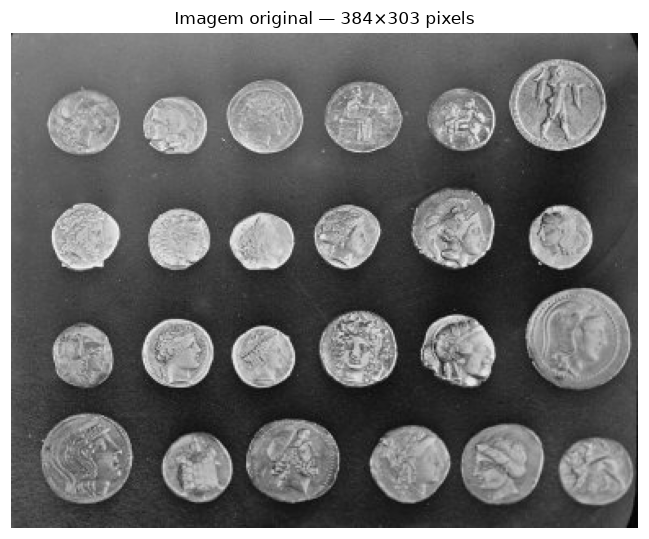

Imagem,Formato,Largura (px),Altura (px)
coins.png,PNG,384,303


In [2]:
CAMINHO=RAIZ/'atividade_4/coins.png'
with Image.open(CAMINHO) as arquivo:
    formato=arquivo.format
    imagem=np.array(arquivo.convert('L'))
altura,largura=imagem.shape

fig,ax=plt.subplots(figsize=(8,5))
ax.imshow(imagem,cmap='gray',vmin=0,vmax=255)
ax.set_title(f'Imagem original — {largura}×{altura} pixels')
ax.axis('off')
finalizar_figura(fig,'01_original')

aquisicao=pd.DataFrame([{'imagem':'coins.png','formato':formato,
                         'largura_px':largura,'altura_px':altura}])
mostrar_tabela(aquisicao,{'imagem':'Imagem','formato':'Formato',
                         'largura_px':'Largura (px)','altura_px':'Altura (px)'},0)

## 3. Segmentação

Na primeira tentativa, foi testado Otsu, que escolhe um único limiar para toda a imagem.
O valor encontrado foi 105. Ele separou várias moedas, mas classificou parte do fundo
mais iluminado como objeto. No canto superior esquerdo, a moeda posteriormente
identificada como objeto 4 ficou conectada ao fundo branco da máscara. Assim, o problema
já aparecia na segmentação, antes da identificação dos componentes.

A comparação com a imagem original mostrou que a dificuldade estava na iluminação
do fundo, não na contagem. A [documentação do OpenCV](https://docs.opencv.org/4.x/d7/d4d/tutorial_py_thresholding.html)
explica por que um limiar local pode ajudar nessa situação e fundamenta a alternativa testada.

Como a iluminação não é uniforme, escolhi a limiarização adaptativa gaussiana, que
calcula um limiar local para cada região. Isso permite rejeitar um fundo claro quando
ele não se destaca da própria vizinhança.

Antes da segmentação, foi aplicado um Gaussiano 3×3 com σ=0,8 para reduzir pequenas
variações. Na limiarização adaptativa foram usados janela 51×51 e `C=-5`. Nesse caso,
o limiar é a média gaussiana local menos C; com C negativo, o pixel precisa ser mais
claro que essa média acrescida de aproximadamente 5 níveis.
Os parâmetros foram escolhidos observando esta imagem e não são universais.

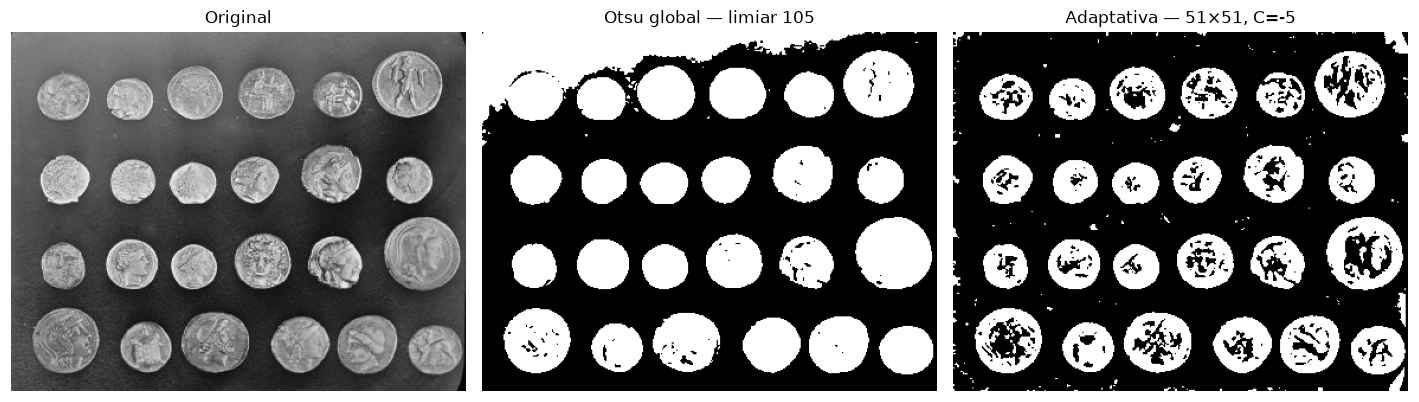

In [3]:
JANELA=51
C=-5
AREA_MINIMA=300

suave=cv2.GaussianBlur(imagem,(3,3),sigmaX=0.8,sigmaY=0.8,
                       borderType=cv2.BORDER_REFLECT_101)
limiar_otsu,otsu=cv2.threshold(suave,0,255,cv2.THRESH_BINARY|cv2.THRESH_OTSU)
segmentada=cv2.adaptiveThreshold(suave,255,cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                cv2.THRESH_BINARY,JANELA,C)

fig,eixos=plt.subplots(1,3,figsize=(13,4))
for eixo,matriz,titulo in zip(eixos,[imagem,otsu,segmentada],
        ['Original',f'Otsu global — limiar {limiar_otsu:.0f}','Adaptativa — 51×51, C=-5']):
    eixo.imshow(matriz,cmap='gray',vmin=0,vmax=255)
    eixo.set_title(titulo);eixo.axis('off')
finalizar_figura(fig,'02_segmentacao')
salvar_mascara(otsu,'otsu')
salvar_mascara(segmentada,'segmentada')

A troca de método melhorou a separação do fundo, mas ainda não resolveu tudo: sobraram
fragmentos e regiões escuras dentro das moedas. Ao observar a máscara, ficou claro que
separar o objeto do fundo não bastava para medir sua silhueta. Por isso, as regiões
internas foram preenchidas nas etapas seguintes. Essa decisão não seria adequada se
os buracos fossem características importantes dos objetos.

Na comparação da mesma moeda do canto superior esquerdo, o componente de Otsu que
continha seu centro tinha 9.700 pixels e alcançava a borda da imagem, pois incluía
fundo. Na máscara adaptativa, antes da morfologia, a região tinha 1.088 pixels e já
estava separada da borda. Portanto, a separação principal dessa moeda ocorreu na
limiarização local; as etapas seguintes refinam sua máscara. Essas áreas descrevem
os componentes obtidos, não uma medida de referência da moeda real.

## 4. Operações morfológicas

Foram aplicadas duas operações pedidas no enunciado:

- **Abertura com elipse 3×3:** tenta remover pontos e pequenas regiões isoladas.
- **Fechamento com elipse 5×5:** tenta fechar pequenas interrupções e lacunas.

Depois, os buracos internos foram preenchidos para representar as moedas como silhuetas.
O preenchimento é uma etapa complementar: ao contrário do fechamento, ele também alcança
cavidades maiores que estejam completamente cercadas pelo objeto.

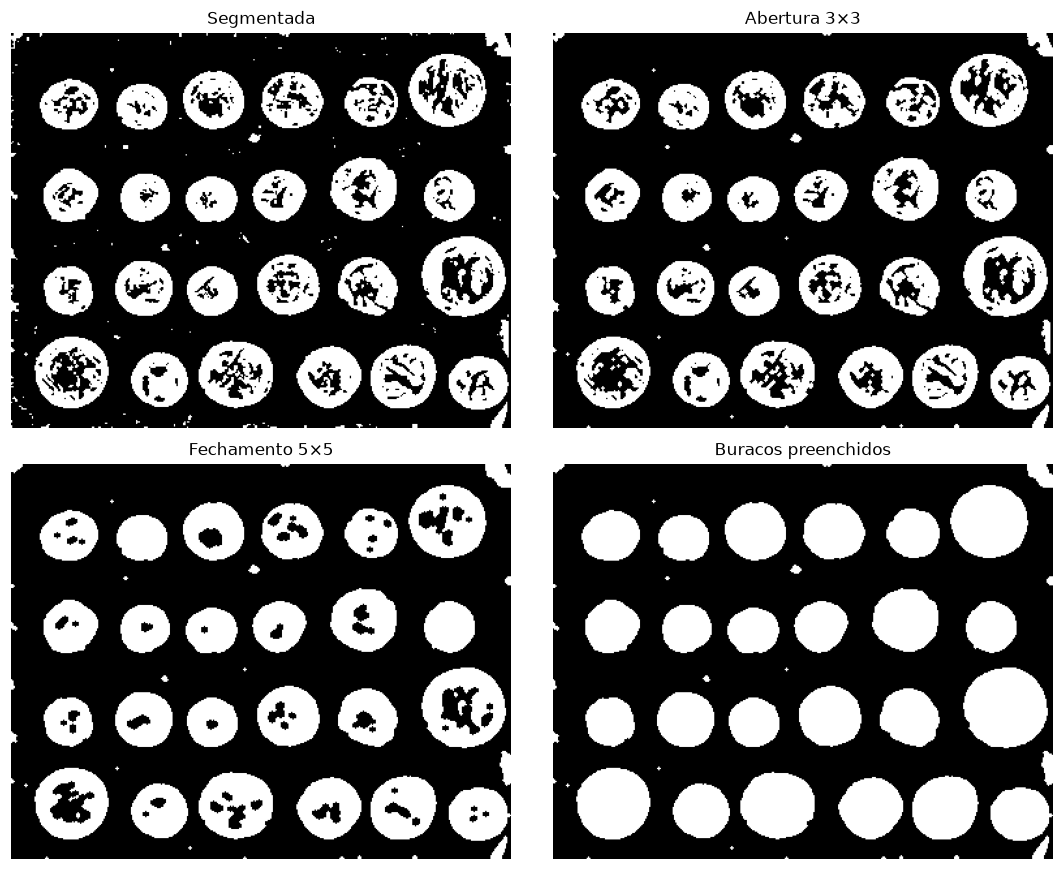

Etapa,Área total (px),Componentes brutos
Segmentada,32952,178
Abertura 3×3,31933,67
Fechamento 5×5,35467,51
Buracos preenchidos,39897,48


In [4]:
K_ABERTURA=cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(3,3))
K_FECHAMENTO=cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(5,5))

def preencher_buracos(mascara):
    moldura=np.pad(mascara,1,constant_values=0).astype(np.uint8)
    exterior=moldura.copy()
    cv2.floodFill(exterior,None,(0,0),255,flags=4)
    return (moldura|cv2.bitwise_not(exterior))[1:-1,1:-1].copy()

aberta=cv2.morphologyEx(segmentada,cv2.MORPH_OPEN,K_ABERTURA,
                        borderType=cv2.BORDER_REPLICATE)
fechada=cv2.morphologyEx(aberta,cv2.MORPH_CLOSE,K_FECHAMENTO,
                         borderType=cv2.BORDER_REPLICATE)
preenchida=preencher_buracos(fechada)

ETAPAS={'Segmentada':segmentada,'Abertura 3×3':aberta,
        'Fechamento 5×5':fechada,'Buracos preenchidos':preenchida}
fig,eixos=plt.subplots(2,2,figsize=(10,8))
linhas=[]
for eixo,(nome,matriz) in zip(eixos.flat,ETAPAS.items()):
    eixo.imshow(matriz,cmap='gray',vmin=0,vmax=255)
    eixo.set_title(nome);eixo.axis('off')
    quantidade=cv2.connectedComponents(matriz,connectivity=8)[0]-1
    linhas.append({'etapa':nome,'pixels_primeiro_plano':int(np.count_nonzero(matriz)),
                   'componentes_brutos':quantidade})
finalizar_figura(fig,'03_morfologia')

for nome,matriz in [('abertura',aberta),('fechamento',fechada),('preenchida',preenchida)]:
    salvar_mascara(matriz,nome)
morfologia=pd.DataFrame(linhas)
morfologia.to_csv(TABELAS/'morfologia.csv',index=False)
mostrar_tabela(morfologia,{'etapa':'Etapa','pixels_primeiro_plano':'Área total (px)',
                           'componentes_brutos':'Componentes brutos'},0)

A abertura reduziu pequenos fragmentos, enquanto o fechamento conectou interrupções e
aumentou algumas regiões. O preenchimento completou as áreas internas. Essas operações
melhoraram as silhuetas, mas também alteraram seus tamanhos; por isso, não devem ser
interpretadas como uma correção perfeita.

A quantidade de componentes caiu de 178 na segmentação para 67 após a abertura,
51 após o fechamento e 48 após o preenchimento. Portanto, a máscara não ficou pronta
de uma só vez: cada etapa tratou fragmentos, interrupções ou cavidades antes da contagem.

## 5. Identificação de objetos

Os componentes conectados foram calculados com conectividade 8. Componentes menores que
300 pixels foram descartados porque são muito menores que as moedas visíveis. O fundo tem
rótulo zero e não entra na contagem.

A primeira contagem da máscara preenchida ainda indicou 48 componentes, acima das
24 moedas visíveis. Conferindo a máscara, havia pequenos fragmentos separados dos
objetos maiores. A seleção por área foi usada para contornar esse excesso de regiões.

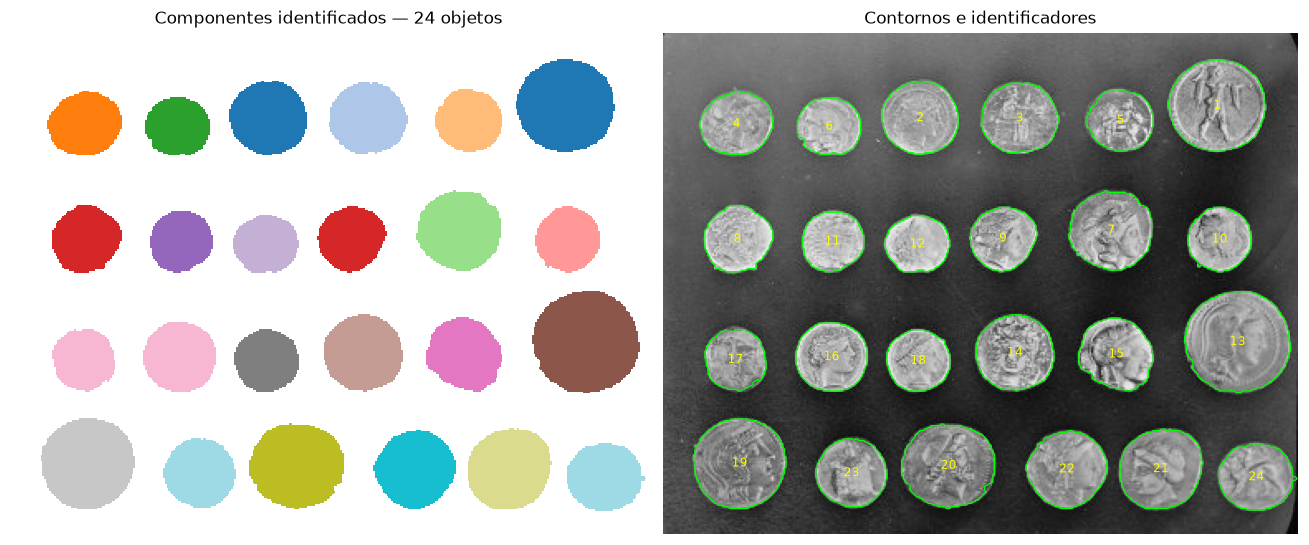

Foram encontrados **24 objetos**. Antes da seleção por área havia **48 componentes**. A contagem visual de referência é 24.

In [5]:
def selecionar_componentes(mascara,area_minima):
    n,rotulos,estatisticas,_=cv2.connectedComponentsWithStats(mascara,connectivity=8)
    aceitos=[i for i in range(1,n) if estatisticas[i,cv2.CC_STAT_AREA]>=area_minima]
    limpa=np.isin(rotulos,aceitos).astype(np.uint8)*255
    n_final,labels,_,centroides=cv2.connectedComponentsWithStats(limpa,connectivity=8)
    return limpa,labels,centroides,n-1,n_final-1

final,rotulos,centroides,componentes_brutos,total=selecionar_componentes(preenchida,AREA_MINIMA)
salvar_mascara(final,'mascara_final')

fig,eixos=plt.subplots(1,2,figsize=(12,5))
eixos[0].imshow(np.ma.masked_equal(rotulos,0),cmap='tab20',interpolation='nearest')
eixos[0].set_title(f'Componentes identificados — {total} objetos')
eixos[1].imshow(imagem,cmap='gray',vmin=0,vmax=255)
for identificador in range(1,total+1):
    mascara=(rotulos==identificador).astype(np.uint8)
    contornos,_=cv2.findContours(mascara,cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_NONE)
    for contorno in contornos:
        pontos=contorno[:,0,:]
        eixos[1].plot(pontos[:,0],pontos[:,1],color='lime',linewidth=0.8)
    x,y=centroides[identificador]
    eixos[1].text(x,y,str(identificador),ha='center',va='center',color='yellow',fontsize=8)
eixos[1].set_title('Contornos e identificadores')
for eixo in eixos:eixo.axis('off')
finalizar_figura(fig,'04_objetos')
display(Markdown(f'Foram encontrados **{total} objetos**. Antes da seleção por área havia '
                 f'**{componentes_brutos} componentes**. A contagem visual de referência é 24.'))

Os 24 componentes correspondem visualmente às 24 moedas. Entretanto, a contagem correta
não garante contornos perfeitos. A moeda inferior direita está próxima da borda e sua
máscara pode incluir parte do fundo. Fragmentos, objetos unidos ou moedas parcialmente
visíveis também poderiam causar erros em outras imagens.

A seleção por área foi eficaz porque o maior componente descartado tinha 259 pixels,
enquanto o menor mantido tinha 1.098 pixels. O limite de 300 separou esses dois grupos
nesta imagem. A quantidade 24 não foi imposta ao algoritmo: resultou das regiões
conectadas que passaram pelo critério. Identificar aqui significa atribuir um número
a cada região, não reconhecer o tipo ou o valor de uma moeda.

A moeda do canto superior esquerdo recebeu o identificador 4 e ficou com 1.350 pixels
na máscara final. A diferença em relação aos 1.088 pixels da segmentação adaptativa
mostra que a morfologia e o preenchimento também modificam as medidas.

## 6. Extração de características

Para cada moeda foram calculadas três características:

- **Área:** quantidade de pixels pertencentes ao componente.
- **Perímetro:** comprimento do contorno externo estimado pelo OpenCV.
- **Centroide:** posição média dos pixels, em coordenadas X e Y.

As medidas estão em pixels porque não existe calibração para convertê-las em milímetros.

A extração usa as regiões já separadas: conta pixels, estima contornos e calcula a
posição média. Ela não corrige a segmentação. Se a moeda continuasse unida ao fundo,
área, perímetro e centroide descreveriam essa região misturada. Um cálculo correto
sobre a máscara não garante uma medida exata do objeto real.

Objeto,Área (px),Perímetro (px),Centroide X,Centroide Y
1,2609,189.92,334.79,43.56
2,1650,150.37,155.26,50.99
3,1605,149.78,215.29,51.20
4,1350,136.47,44.26,54.58
5,1209,128.23,276.43,52.62
6,1103,123.74,100.29,56.21
7,1931,163.20,270.68,118.99
8,1314,134.47,44.80,124.30
9,1231,130.12,205.28,123.85
10,1198,128.47,336.18,124.44


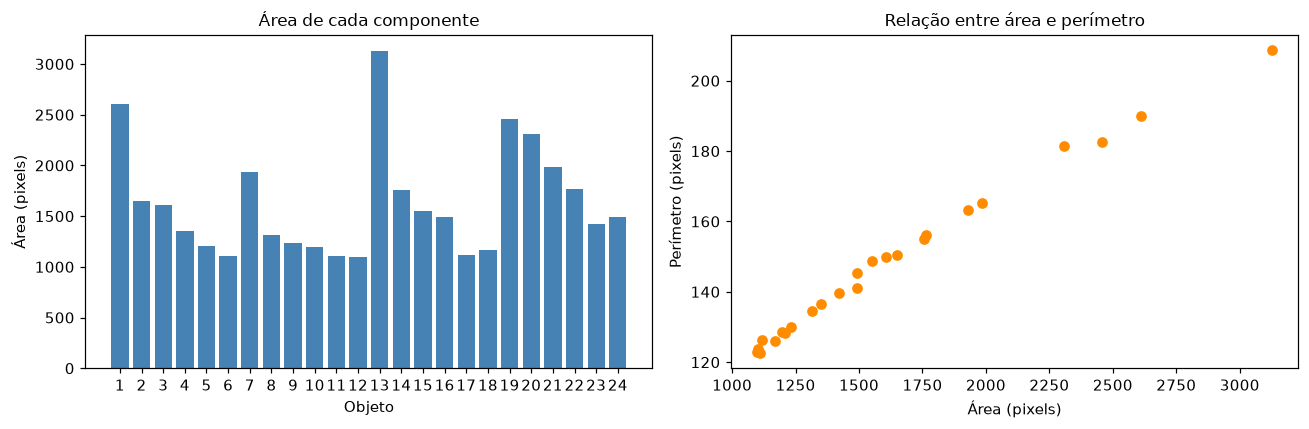

A menor região é o objeto **12**, com **1098 pixels**; a maior é o objeto **13**, com **3128 pixels**.

In [6]:
def extrair_caracteristicas(labels):
    linhas=[]
    for identificador in np.unique(labels):
        if identificador==0:
            continue
        mascara=labels==identificador
        ys,xs=np.nonzero(mascara)
        contornos,_=cv2.findContours(mascara.astype(np.uint8),cv2.RETR_EXTERNAL,
                                     cv2.CHAIN_APPROX_NONE)
        perimetro=sum(cv2.arcLength(c,True) for c in contornos)
        linhas.append({'objeto':int(identificador),'area_px':int(mascara.sum()),
                       'perimetro_px':float(perimetro),'centroide_x':float(xs.mean()),
                       'centroide_y':float(ys.mean())})
    return pd.DataFrame(linhas)

caracteristicas=extrair_caracteristicas(rotulos)
caracteristicas.to_csv(TABELAS/'caracteristicas.csv',index=False)
mostrar_tabela(caracteristicas,{'objeto':'Objeto','area_px':'Área (px)',
    'perimetro_px':'Perímetro (px)','centroide_x':'Centroide X','centroide_y':'Centroide Y'})

fig,eixos=plt.subplots(1,2,figsize=(12,4))
eixos[0].bar(caracteristicas.objeto,caracteristicas.area_px,color='steelblue')
eixos[0].set(xlabel='Objeto',ylabel='Área (pixels)',title='Área de cada componente')
eixos[0].set_xticks(caracteristicas.objeto)
eixos[1].scatter(caracteristicas.area_px,caracteristicas.perimetro_px,color='darkorange')
eixos[1].set(xlabel='Área (pixels)',ylabel='Perímetro (pixels)',
             title='Relação entre área e perímetro')
finalizar_figura(fig,'05_caracteristicas')

menor=caracteristicas.loc[caracteristicas.area_px.idxmin()]
maior=caracteristicas.loc[caracteristicas.area_px.idxmax()]
display(Markdown(f'A menor região é o objeto **{int(menor.objeto)}**, com '
                 f'**{int(menor.area_px)} pixels**; a maior é o objeto '
                 f'**{int(maior.objeto)}**, com **{int(maior.area_px)} pixels**.'))

## 7. Análise dos resultados

O principal ganho ocorreu ao trocar o limiar global por um limiar local na mesma
imagem. O caso da moeda 4 mostra a diferença: com Otsu, ela se conectou ao fundo claro;
com a adaptativa, ficou isolada antes das operações morfológicas. Essa separação
permitiu que a identificação e a extração trabalhassem sobre uma região individual.

Uma verificação complementar mostrou que o ajuste de C também importava: mantendo
as outras etapas, `C=-3` produziu 25 regiões e `C=0` produziu 30, enquanto `C=-5`
resultou em 24. Portanto, não bastou trocar o nome do método; foi necessário comparar
as máscaras e conferir quais regiões estavam sendo incluídas.

Área e perímetro foram as características mais informativas para comparar o tamanho das
moedas. Elas são relacionadas: objetos maiores normalmente apresentam valores maiores nas
duas medidas. O centroide informa a posição de cada moeda e ajuda a localizar o objeto,
mas não identifica seu tipo.

As características permitem separar visualmente moedas grandes de pequenas, porém não são
suficientes para classificar todas por tipo ou valor. Moedas diferentes podem ter áreas e
perímetros próximos. Para essa tarefa seriam necessários rótulos de classe e descritores
de textura ou aparência.

A contagem de 24 objetos corresponde à inspeção visual, mas não comprova 100% de precisão
dos contornos ou das características. Os parâmetros foram ajustados observando esta
imagem, e ainda não foram avaliados em novas capturas. Para medir a qualidade da
segmentação, seria necessário comparar as máscaras com contornos de referência anotados.

O principal limite está na segmentação: qualquer pixel incluído ou removido modifica as
medidas. O preenchimento foi adequado para estudar silhuetas, mas eliminaria buracos reais.
O pipeline poderia ser melhorado com correção de iluminação, contornos anotados para
avaliação e testes em outras imagens. Se moedas estivessem encostadas, seria necessário
um método adicional de separação, como watershed.

## 8. Conclusão

A limiarização adaptativa foi mais adequada que Otsu porque o fundo apresenta variação de
iluminação. Ela separou a moeda do canto superior esquerdo, identificada depois como
objeto 4, que no limiar global se misturava ao fundo branco. A abertura, o fechamento
e o preenchimento refinaram as máscaras. A seleção por área reduziu os 48 componentes
restantes para 24 objetos, correspondentes visualmente às 24 moedas, sem impor essa
quantidade ao algoritmo.

Área e perímetro distinguiram principalmente o tamanho dos objetos, enquanto o centroide
indicou sua localização. Essas características descrevem as regiões encontradas, mas não
determinam o tipo ou o valor das moedas.

O resultado foi satisfatório para contagem e comparação de tamanho nesta imagem.
Entretanto, as medidas dependem das máscaras, que foram alteradas pela morfologia e
podem incluir erros de contorno. Acertar a quantidade de moedas não demonstra precisão
total da segmentação ou da extração. A validação com contornos anotados e outras imagens
seria necessária para avaliar a exatidão das medidas e a aplicação dos mesmos parâmetros.

As tentativas mostraram a importância de conferir cada etapa: primeiro a separação do
fundo, depois os fragmentos e, por último, as medidas. Executar sem erro não foi suficiente
para decidir se o resultado representava bem as moedas.

### Referências

- Enunciado: *Atividade Prática*, Unidade 3, Capítulo 1, Prof. Alyson Bezerra.
- [Scikit-image — imagem coins](https://scikit-image.org/docs/stable/api/skimage.data.html#skimage.data.coins).
- [OpenCV — limiarização](https://docs.opencv.org/4.x/d7/d4d/tutorial_py_thresholding.html).
- [OpenCV — operações morfológicas](https://docs.opencv.org/4.x/d9/d61/tutorial_py_morphological_ops.html).
- [OpenCV — componentes e contornos](https://docs.opencv.org/4.x/d3/dc0/group__imgproc__shape.html).